# EDA: Dự đoán lưu lượng giao thông theo giờ
**Người thực hiện:** Phùng Anh Vũ  
**Mục tiêu:** Tìm hiểu dữ liệu, trực quan hóa lưu lượng theo thời gian và thời tiết, ghi nhận các phát hiện phục vụ nhóm. Các biểu đồ mô tả mối liên hệ, không chứng minh quan hệ nhân quả.

Nguồn dữ liệu: [UCI Metro Interstate Traffic Volume](https://archive.ics.uci.edu/dataset/492/metro+interstate+traffic+volume). Dữ liệu ghi nhận lưu lượng theo giờ trên tuyến I-94 hướng tây cùng thông tin thời tiết và ngày lễ.

EDA mô tả trên toàn CSV theo [trang 2 của sơ đồ](../../docs/Quy%20tr%C3%ACnh.drawio). Các biểu đồ lưu lượng theo thời gian tính trên một dòng mỗi giờ. Bảng kiểm tra nhãn và bản ghi bất thường ghi rõ khi dùng dòng gốc.

In [12]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("ggplot")
pd.set_option("display.max_columns", None)
project = next((p for p in (Path.cwd(), *Path.cwd().parents, Path.cwd() / "metro_interstate_traffic_volume") if (p / "data" / "Metro_Interstate_Traffic_Volume.csv").exists()), Path.cwd())
path = project / "data" / "Metro_Interstate_Traffic_Volume.csv"
if not path.exists():
    raise FileNotFoundError(f"Không tìm thấy dữ liệu: {path}")
df = pd.read_csv(path, keep_default_na=False)
df["date_time"] = pd.to_datetime(df["date_time"], errors="raise")
print("Kích thước:", df.shape)
display(df.head())

assert df["date_time"].notna().all() and df["date_time"].eq(df["date_time"].dt.floor("h")).all()

Kích thước: (48204, 9)


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,None,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,None,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,None,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,None,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,None,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


## 1. Tổng quan dữ liệu
`traffic_volume` là số xe/giờ; `temp` đo bằng Kelvin; `rain_1h` và `snow_1h` là lượng mưa/tuyết trong giờ; `clouds_all` là phần trăm mây che phủ. Các trường `holiday`, `weather_main`, `weather_description` mô tả ngày lễ và thời tiết.

In [13]:
df.info()
display(df.describe(include="all").T)
print("Khoảng thời gian:", df.date_time.min(), "đến", df.date_time.max())
print("Số dòng trùng hoàn toàn:", df.duplicated().sum())
print("Số timestamp lặp:", df.date_time.duplicated().sum())
print("Số ngày giờ không hợp lệ:", df["date_time"].isna().sum())
display(pd.DataFrame({"null": df.isna().sum(), "rỗng": df.astype("string").apply(lambda s: s.str.strip().eq("").sum())}))

<class 'pandas.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   holiday              48204 non-null  str           
 1   temp                 48204 non-null  float64       
 2   rain_1h              48204 non-null  float64       
 3   snow_1h              48204 non-null  float64       
 4   clouds_all           48204 non-null  int64         
 5   weather_main         48204 non-null  str           
 6   weather_description  48204 non-null  str           
 7   date_time            48204 non-null  datetime64[us]
 8   traffic_volume       48204 non-null  int64         
dtypes: datetime64[us](1), float64(3), int64(2), str(3)
memory usage: 4.3 MB


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
holiday,48204,12,None,48143,NaN,NaN,NaN,NaN,NaN,NaN,NaN
temp,48204.0,NaN,NaN,NaN,281.20587,0.0,272.16,282.45,291.806,310.07,13.338232
rain_1h,48204.0,NaN,NaN,NaN,0.334264,0.0,0.0,0.0,0.0,9831.3,44.789133
snow_1h,48204.0,NaN,NaN,NaN,0.000222,0.0,0.0,0.0,0.0,0.51,0.008168
clouds_all,48204.0,NaN,NaN,NaN,49.362231,0.0,1.0,64.0,90.0,100.0,39.01575
weather_main,48204,11,Clouds,15164,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weather_description,48204,38,sky is clear,11665,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_time,48204,NaN,NaN,NaN,2016-01-05 10:46:16.773711,2012-10-02 09:00:00,2014-02-06 11:45:00,2016-06-11 03:30:00,2017-08-11 06:00:00,2018-09-30 23:00:00,NaN
traffic_volume,48204.0,NaN,NaN,NaN,3259.818355,0.0,1193.0,3380.0,4933.0,7280.0,1986.86067


Khoảng thời gian: 2012-10-02 09:00:00 đến 2018-09-30 23:00:00
Số dòng trùng hoàn toàn: 17
Số timestamp lặp: 7629
Số ngày giờ không hợp lệ: 0


,null,rỗng
holiday,0,0
temp,0,0
rain_1h,0,0
snow_1h,0,0
clouds_all,0,0
weather_main,0,0
weather_description,0,0
date_time,0,0
traffic_volume,0,0


**Nhận xét:** Dữ liệu gồm 48.204 dòng, 9 cột, từ 02/10/2012 đến 30/09/2018. Có 17 dòng trùng hoàn toàn và 7.629 dòng có timestamp đã xuất hiện trước đó. Không phát hiện null hoặc chuỗi rỗng theo phép kiểm tra trên; vẫn cần kiểm tra giá trị bất thường.

### 1.2. Kiểm tra timestamp lặp

Một timestamp có thể xuất hiện nhiều dòng. Phần này kiểm tra các
dòng cùng thời điểm có khác nhau về lưu lượng và thời tiết hay không.


In [14]:
valid_time = df.dropna(subset=["date_time"]).copy()

duplicate_rows = valid_time[
    valid_time.duplicated("date_time", keep=False)
].sort_values("date_time")

print("Số dòng thuộc timestamp lặp:", len(duplicate_rows))
print("Số timestamp bị lặp:", duplicate_rows["date_time"].nunique())

columns_to_check = [
    "traffic_volume",
    "temp",
    "rain_1h",
    "snow_1h",
    "clouds_all",
    "weather_main",
    "weather_description",
]

timestamp_differences = (
    duplicate_rows
    .groupby("date_time")[columns_to_check]
    .nunique(dropna=False)
)

print("Số timestamp có nhiều hơn một giá trị ở từng cột:")
display(
    timestamp_differences.gt(1)
    .sum()
    .rename("so_timestamp")
    .to_frame()
)

print("Ví dụ các dòng có timestamp lặp:")
display(
    duplicate_rows[["date_time"] + columns_to_check].head(10)
)

Số dòng thuộc timestamp lặp: 13074
Số timestamp bị lặp: 5445
Số timestamp có nhiều hơn một giá trị ở từng cột:


,so_timestamp
traffic_volume,0
temp,78
rain_1h,9
snow_1h,0
clouds_all,32
weather_main,5349
weather_description,5386


Ví dụ các dòng có timestamp lặp:


,date_time,traffic_volume,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description
178,2012-10-10 07:00:00,6793,281.25,0.0,0.0,99,Rain,light rain
179,2012-10-10 07:00:00,6793,281.25,0.0,0.0,99,Drizzle,light intensity drizzle
180,2012-10-10 08:00:00,6283,280.10,0.0,0.0,99,Rain,light rain
181,2012-10-10 08:00:00,6283,280.10,0.0,0.0,99,Drizzle,light intensity drizzle
182,2012-10-10 09:00:00,5680,279.61,0.0,0.0,99,Rain,light rain
183,2012-10-10 09:00:00,5680,279.61,0.0,0.0,99,Drizzle,light intensity drizzle
269,2012-10-14 09:00:00,2685,282.43,0.0,0.0,57,Drizzle,light intensity drizzle
270,2012-10-14 09:00:00,2685,282.43,0.0,0.0,57,Mist,mist
271,2012-10-14 09:00:00,2685,282.43,0.0,0.0,57,Haze,haze
272,2012-10-14 10:00:00,3370,282.33,0.0,0.0,57,Drizzle,light intensity drizzle


**Nhận xét:**

- Có 5.445 timestamp xuất hiện nhiều lần, tương ứng 13.074 dòng.
- Không có timestamp nào có các giá trị `traffic_volume` khác nhau.
- Có 5.349 timestamp có nhiều giá trị `weather_main` và 5.386 timestamp
  có nhiều giá trị `weather_description`.
- Do đó, phân tích lưu lượng theo thời gian có thể sử dụng một giá trị
  lưu lượng cho mỗi timestamp. Đối với thời tiết, cần lưu ý rằng một
  timestamp có thể có nhiều mô tả.

In [15]:
conflicts = timestamp_differences.index[timestamp_differences["traffic_volume"].gt(1)]
if len(conflicts):
    raise ValueError(f"Lưu lượng mâu thuẫn tại {len(conflicts)} giờ: {conflicts[:3].tolist()}")

hourly = df[["date_time", "traffic_volume"]].drop_duplicates().sort_values("date_time")
assert hourly["date_time"].is_unique and hourly["traffic_volume"].ge(0).all()
hourly["hour"] = hourly["date_time"].dt.hour
hourly["weekday"] = hourly["date_time"].dt.dayofweek
hourly["month"] = hourly["date_time"].dt.month
print(f"{len(hourly):,} giờ quan sát")
display(hourly.head(3))

40,575 giờ quan sát


,date_time,traffic_volume,hour,weekday,month
0,2012-10-02 09:00:00,5545,9,1,10
1,2012-10-02 10:00:00,4516,10,1,10
2,2012-10-02 11:00:00,4767,11,1,10


### 1.3. Kiểm tra khoảng trống thời gian

So sánh timestamp thực tế với một dãy thời gian liên tục theo giờ
để xác định số giờ và các khoảng thời gian không có dữ liệu.

In [16]:
observed_hours = pd.DatetimeIndex(
    hourly["date_time"].sort_values()
)

expected_hours = pd.date_range(
    start=observed_hours.min(),
    end=observed_hours.max(),
    freq="h"
)

missing_hours = expected_hours.difference(observed_hours)

print("Số giờ có dữ liệu:", len(observed_hours))
print("Số giờ dự kiến:", len(expected_hours))
print("Số giờ không có dữ liệu:", len(missing_hours))

Số giờ có dữ liệu: 40575
Số giờ dự kiến: 52551
Số giờ không có dữ liệu: 11976


In [17]:
if len(missing_hours) > 0:
    missing_series = pd.Series(missing_hours, name="time")

    gap_group = (
        missing_series.diff()
        .ne(pd.Timedelta(hours=1))
        .cumsum()
    )

    gaps = (
        missing_series.groupby(gap_group)
        .agg(
            start="min",
            end="max",
            missing_hours="size"
        )
        .sort_values("missing_hours", ascending=False)
    )

    print("Các khoảng thiếu dài nhất:")
    display(gaps.head(20))
else:
    print("Không có giờ bị thiếu trong khoảng thời gian khảo sát.")

Các khoảng thiếu dài nhất:


,start,end,missing_hours
time,,,
896,2014-08-08 02:00:00,2015-06-11 19:00:00,7386
664,2013-10-27 02:00:00,2013-11-06 03:00:00,242
902,2015-06-14 21:00:00,2015-06-19 17:00:00,117
783,2014-04-29 09:00:00,2014-05-04 04:00:00,116
1024,2015-10-23 12:00:00,2015-10-27 07:00:00,92
889,2014-07-27 17:00:00,2014-07-30 08:00:00,64
416,2013-08-31 01:00:00,2013-09-01 22:00:00,46
906,2015-06-22 19:00:00,2015-06-24 03:00:00,33
893,2014-08-02 03:00:00,2014-08-03 10:00:00,32


,observed_hours,total_hours,coverage_pct
2012-10-01,667,711,93.811533
2012-11-01,706,720,98.055556
2012-12-01,730,744,98.118280
2013-01-01,605,744,81.317204
2013-02-01,594,672,88.392857
...,...,...,...
2018-05-01,743,744,99.865591
2018-06-01,719,720,99.861111
2018-07-01,744,744,100.000000
2018-08-01,740,744,99.462366


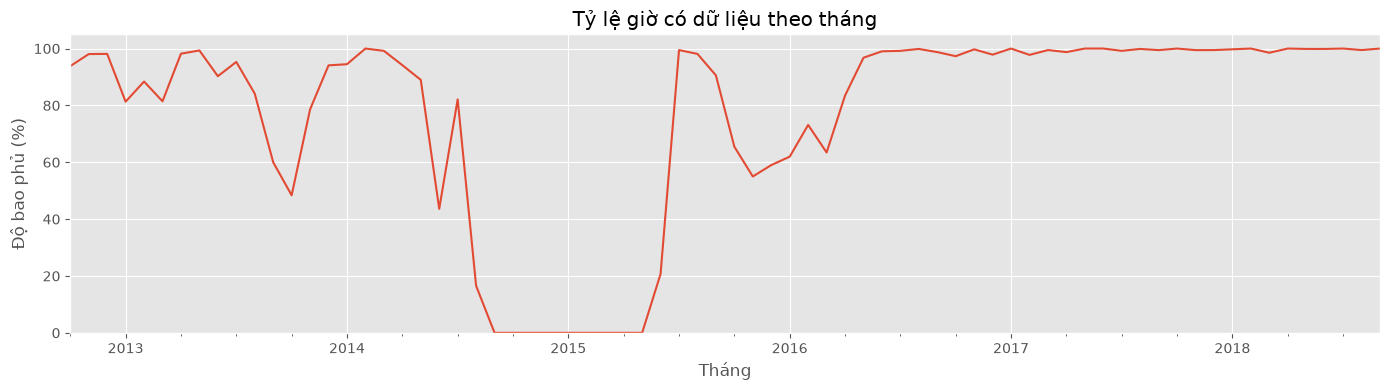

In [18]:
coverage = pd.DataFrame(index=expected_hours)
coverage["observed"] = coverage.index.isin(observed_hours)

monthly_coverage = coverage["observed"].resample("MS").agg(
    observed_hours="sum",
    total_hours="size"
)

monthly_coverage["coverage_pct"] = (
    monthly_coverage["observed_hours"]
    / monthly_coverage["total_hours"]
    * 100
)

display(monthly_coverage)

fig, ax = plt.subplots(figsize=(14, 4))

monthly_coverage["coverage_pct"].plot(ax=ax)

ax.set(
    title="Tỷ lệ giờ có dữ liệu theo tháng",
    xlabel="Tháng",
    ylabel="Độ bao phủ (%)",
    ylim=(0, 105)
)

plt.tight_layout()
plt.show()

**Nhận xét:**

- Trong khoảng từ timestamp đầu tiên đến timestamp cuối cùng, có
  11.976 giờ không có bản ghi.
- Khoảng thiếu liên tiếp dài nhất gồm 7.386 giờ, từ 08/08/2014 02:00
  đến 11/06/2015 19:00.
- Độ bao phủ giữa các tháng không đồng đều; có những tháng không có
  bản ghi.
- Vì vậy, khi so sánh lưu lượng trung bình theo tháng cần xét thêm
  tỷ lệ bao phủ và thận trọng khi diễn giải kết quả.
- Những giờ thiếu không được tự động coi là giờ có lưu lượng bằng 0.

### 1.4. Kiểm tra giá trị bất thường

Kiểm tra phạm vi và phân bố của các biến số để xác định những giá trị
không hợp lệ hoặc cần xác minh thêm.

In [19]:
numeric_cols = [
    "temp",
    "rain_1h",
    "snow_1h",
    "clouds_all",
    "traffic_volume",
]

display(
    df[numeric_cols].describe(
        percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]
    ).T
)

,count,mean,std,min,1%,5%,50%,95%,99%,max
temp,48204.0,281.205870,13.338232,0.0,250.7803,258.34,282.45,299.29,302.82,310.07
rain_1h,48204.0,0.334264,44.789133,0.0,0.0000,0.00,0.00,0.30,3.27,9831.30
snow_1h,48204.0,0.000222,0.008168,0.0,0.0000,0.00,0.00,0.00,0.00,0.51
clouds_all,48204.0,49.362231,39.015750,0.0,0.0000,1.00,64.00,90.00,92.00,100.00
traffic_volume,48204.0,3259.818355,1986.860670,0.0,257.0000,339.00,3380.00,6197.00,6701.97,7280.00


In [20]:
checks = {
    "Nhiệt độ <= 0 K": df["temp"] <= 0,
    "Lượng mưa âm": df["rain_1h"] < 0,
    "Lượng tuyết âm": df["snow_1h"] < 0,
    "Mây ngoài khoảng 0–100%": ~df["clouds_all"].between(0, 100),
    "Lưu lượng âm": df["traffic_volume"] < 0,
    "Lưu lượng bằng 0": df["traffic_volume"] == 0,
}

check_counts = pd.Series(
    {name: int(mask.sum()) for name, mask in checks.items()},
    name="so_dong"
)

display(check_counts.to_frame())

,so_dong
Nhiệt độ <= 0 K,10
Lượng mưa âm,0
Lượng tuyết âm,0
Mây ngoài khoảng 0–100%,0
Lưu lượng âm,0
Lưu lượng bằng 0,2


In [21]:
display_cols = [
    "date_time",
    "temp",
    "rain_1h",
    "snow_1h",
    "clouds_all",
    "traffic_volume",
    "weather_main",
    "weather_description",
]

print("Các dòng có nhiệt độ <= 0 K:")
display(
    df.loc[df["temp"] <= 0, display_cols]
    .sort_values("date_time")
)

print("10 dòng có lượng mưa lớn nhất:")
display(df.nlargest(10, "rain_1h")[display_cols])

print("Các timestamp có lưu lượng bằng 0:")
display(
    hourly.loc[
        hourly["traffic_volume"] == 0,
        ["date_time", "traffic_volume"]
    ]
)

Các dòng có nhiệt độ <= 0 K:


,date_time,temp,rain_1h,snow_1h,clouds_all,traffic_volume,weather_main,weather_description
11898,2014-01-31 03:00:00,0.0,0.0,0.0,0,361,Clear,sky is clear
11899,2014-01-31 04:00:00,0.0,0.0,0.0,0,734,Clear,sky is clear
11900,2014-01-31 05:00:00,0.0,0.0,0.0,0,2557,Clear,sky is clear
11901,2014-01-31 06:00:00,0.0,0.0,0.0,0,5150,Clear,sky is clear
11946,2014-02-02 03:00:00,0.0,0.0,0.0,0,291,Clear,sky is clear
11947,2014-02-02 04:00:00,0.0,0.0,0.0,0,284,Clear,sky is clear
11948,2014-02-02 05:00:00,0.0,0.0,0.0,0,434,Clear,sky is clear
11949,2014-02-02 06:00:00,0.0,0.0,0.0,0,739,Clear,sky is clear
11950,2014-02-02 07:00:00,0.0,0.0,0.0,0,962,Clear,sky is clear
11951,2014-02-02 08:00:00,0.0,0.0,0.0,0,1670,Clear,sky is clear


10 dòng có lượng mưa lớn nhất:


,date_time,temp,rain_1h,snow_1h,clouds_all,traffic_volume,weather_main,weather_description
24872,2016-07-11 17:00:00,302.11,9831.30,0.0,75,5535,Rain,very heavy rain
8247,2013-08-07 02:00:00,289.10,55.63,0.0,68,315,Rain,very heavy rain
7179,2013-06-24 11:00:00,295.82,44.45,0.0,76,4802,Rain,very heavy rain
25779,2016-08-16 17:00:00,297.71,31.75,0.0,0,4913,Rain,very heavy rain
10806,2013-12-19 23:00:00,264.50,28.70,0.0,64,1190,Rain,very heavy rain
10807,2013-12-19 23:00:00,264.50,28.70,0.0,64,1190,Snow,light snow
16504,2015-07-13 00:00:00,292.02,27.57,0.0,90,492,Rain,very heavy rain
16505,2015-07-13 00:00:00,292.02,27.57,0.0,90,492,Thunderstorm,proximity thunderstorm
16506,2015-07-13 00:00:00,292.02,27.57,0.0,90,492,Mist,mist
17437,2015-08-16 21:00:00,294.49,25.46,0.0,90,2118,Rain,very heavy rain


Các timestamp có lưu lượng bằng 0:


,date_time,traffic_volume
25186,2016-07-23 18:00:00,0
25191,2016-07-23 23:00:00,0


In [22]:
window = hourly["date_time"].between("2016-07-23 09:00", "2016-07-24 04:00")
display(hourly.loc[window, "traffic_volume"].agg(["size", "min", "median", "max"]))
rain = df["rain_1h"]
print(f"Mưa P99: {rain.quantile(.99):.2f} mm | Cực đại: {rain.max():,.1f} mm")
repeated_temp = df.loc[df["temp"].eq(276.793), "date_time"]
print(f"276,793 K xuất hiện ở {repeated_temp.nunique()} giờ, từ {repeated_temp.min()} đến {repeated_temp.max()}")

size      20.0
min        0.0
median     4.0
max       24.0
Name: traffic_volume, dtype: float64

Mưa P99: 3.27 mm | Cực đại: 9,831.3 mm
276,793 K xuất hiện ở 78 giờ, từ 2013-10-22 05:00:00 đến 2014-01-23 08:00:00


**Phân loại.** Có 10 dòng nhiệt độ 0 K, không phù hợp với nhiệt độ môi trường. Mưa cực đại 9.831,3 mm trong khi P99 là 3,27 mm, nên cần đối chiếu đơn vị và bản ghi. Trang 2 đánh dấu hai loại điểm này là thiếu. Hai giờ 0 xe nằm trong đoạn 20 giờ liên tiếp có lưu lượng 0–24 xe/giờ, trung vị 4 xe/giờ. Giữ các giờ đó để đối chiếu bối cảnh trạm. Mức nhiệt lặp 276,793 K là dấu hiệu cần xem chuỗi quan sát trước khi kết luận lỗi đo.

### 1.5. Boxplot và ngưỡng IQR

Điểm ngoài `[Q1 − 1,5 × IQR; Q3 + 1,5 × IQR]` được gắn cờ để xem xét. Bảng dưới tính thời tiết trên dòng gốc và lưu lượng trên giờ duy nhất.

In [23]:
def iqr_stats(s):
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return pd.Series({"Q1": q1, "Q3": q3, "Cận dưới": lo, "Cận trên": hi,
                      "Dưới cận": s.lt(lo).sum(), "Trên cận": s.gt(hi).sum()})

weather_cols = ["temp", "rain_1h", "snow_1h", "clouds_all"]
display(df[weather_cols].apply(iqr_stats).T.round(2))
display(iqr_stats(hourly["traffic_volume"]).to_frame("Lưu lượng theo giờ").T)

,Q1,Q3,Cận dưới,Cận trên,Dưới cận,Trên cận
temp,272.16,291.81,242.69,321.27,10.0,0.0
rain_1h,0.00,0.00,0.00,0.00,0.0,3467.0
snow_1h,0.00,0.00,0.00,0.00,0.0,63.0
clouds_all,1.00,90.00,-132.50,223.50,0.0,0.0


,Q1,Q3,Cận dưới,Cận trên,Dưới cận,Trên cận
Lưu lượng theo giờ,1248.5,4952.0,-4306.75,10507.25,0.0,0.0


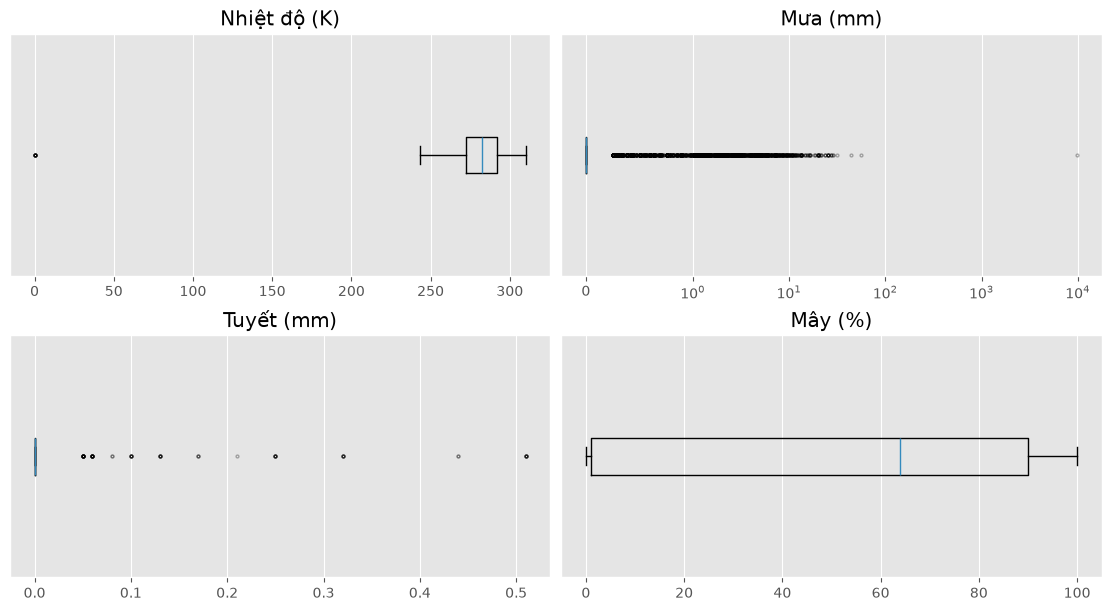

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6), layout="constrained")
for ax, col, title in zip(axes.flat, weather_cols, ["Nhiệt độ (K)", "Mưa (mm)", "Tuyết (mm)", "Mây (%)"]):
    ax.boxplot(df[col], orientation="horizontal", flierprops={"markersize": 2, "alpha": .3})
    ax.set(title=title, yticks=[])
    if col == "rain_1h":
        ax.set_xscale("symlog", linthresh=1)
plt.show()

**Nhận xét.** Với mưa và tuyết, Q1 và Q3 đều bằng 0 nên mọi giá trị dương nằm ngoài râu hộp, kể cả quan sát có mưa hoặc tuyết hợp lý. Điểm mưa 9.831,3 mm được xem riêng dựa trên độ lớn và ngữ cảnh. Lưu lượng có cận IQR từ −4.306,75 đến 10.507,25 xe/giờ và 0 điểm ngoài cận. Hai giờ 0 xe vẫn cần xem theo chuỗi thời gian.

### 1.6. Chuẩn hóa cách viết mô tả thời tiết

In [25]:
print("Các giá trị weather_description:")
display(
    df["weather_description"]
    .value_counts(dropna=False)
    .rename("so_dong")
    .to_frame()
)

df["weather_description_clean"] = (
    df["weather_description"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
    .str.lower()
)

description_variants = (
    df.groupby("weather_description_clean")["weather_description"]
    .agg(lambda values: sorted(values.dropna().unique()))
)

print("Các nội dung có nhiều cách viết gốc:")
display(
    description_variants[
        description_variants.map(len) > 1
    ].to_frame(name="cac_cach_viet_goc")
)

Các giá trị weather_description:


,so_dong
weather_description,
sky is clear,11665
mist,5950
overcast clouds,5081
broken clouds,4666
scattered clouds,3461
light rain,3372
few clouds,1956
light snow,1946
Sky is Clear,1726


Các nội dung có nhiều cách viết gốc:


,cac_cach_viet_goc
weather_description_clean,
sky is clear,"[Sky is Clear, sky is clear]"


In [26]:
weather_mapping = (
    df.groupby(
        ["weather_main", "weather_description_clean"],
        dropna=False
    )
    .size()
    .reset_index(name="so_dong")
    .sort_values(
        ["weather_main", "so_dong"],
        ascending=[True, False]
    )
)

display(weather_mapping)

,weather_main,weather_description_clean,so_dong
0,Clear,sky is clear,13391
3,Clouds,overcast clouds,5081
1,Clouds,broken clouds,4666
4,Clouds,scattered clouds,3461
2,Clouds,few clouds,1956
7,Drizzle,light intensity drizzle,1100
5,Drizzle,drizzle,651
6,Drizzle,heavy intensity drizzle,64
8,Drizzle,shower drizzle,6
9,Fog,fog,912


**Nhận xét:**

- Phát hiện nhóm mô tả `sky is clear` có hai cách viết gốc khác nhau.
- Việc chuẩn hóa chữ hoa/thường và khoảng trắng giúp các cách viết có
  cùng nội dung được thống kê chung.
- Cột `weather_description` được giữ nguyên; cột
  `weather_description_clean` được tạo để hỗ trợ phân tích.
- Các kết hợp giữa `weather_main` và mô tả cần tiếp tục được xem xét
  theo ngữ cảnh, không tự động xem là lỗi.

## 2. Phân bố lưu lượng

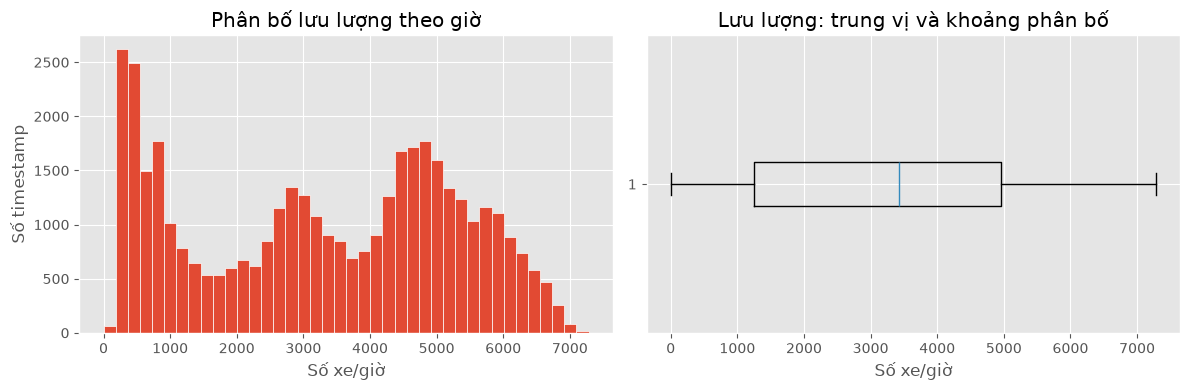

count    40575.000000
mean      3290.650474
std       1984.772909
min          0.000000
25%       1248.500000
50%       3427.000000
75%       4952.000000
max       7280.000000
Name: traffic_volume, dtype: float64

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(hourly.traffic_volume, bins=40, edgecolor="white")
ax[0].set(title="Phân bố lưu lượng theo giờ", xlabel="Số xe/giờ", ylabel="Số timestamp")
ax[1].boxplot(hourly.traffic_volume, orientation="horizontal")
ax[1].set(title="Lưu lượng: trung vị và khoảng phân bố", xlabel="Số xe/giờ")
plt.tight_layout()
plt.show()
display(hourly.traffic_volume.describe())

**Nhận xét:**

- Sau khi gộp theo timestamp, dữ liệu có 40.575 giờ được ghi nhận.
- Lưu lượng trung bình khoảng 3.291 xe/giờ và trung vị khoảng
  3.427 xe/giờ.
- Lưu lượng trải rộng từ 0 đến 7.280 xe/giờ, cho thấy mức giao thông
  thay đổi đáng kể giữa các thời điểm.
- Hai timestamp có lưu lượng bằng 0 đã được liệt kê ở mục 1.4 và cần
  được kiểm tra thêm.

## 3. Lưu lượng theo thời gian

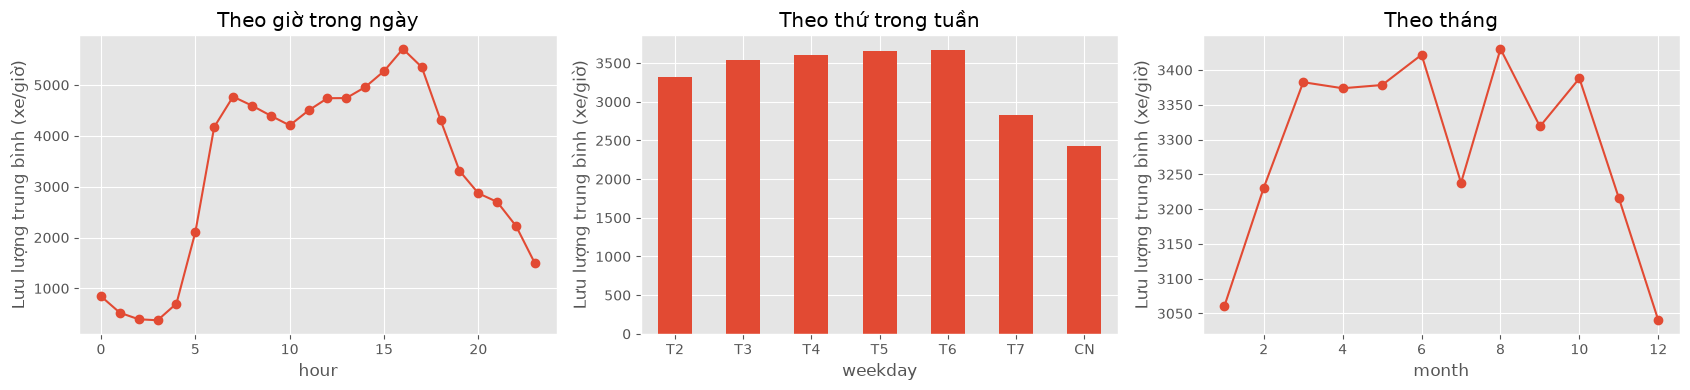

Giờ trung bình cao nhất: 16


In [28]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
hourly.groupby("hour").traffic_volume.mean().plot(ax=axes[0], marker="o", title="Theo giờ trong ngày")
hourly.groupby("weekday").traffic_volume.mean().plot.bar(ax=axes[1], title="Theo thứ trong tuần")
axes[1].set_xticklabels(["T2", "T3", "T4", "T5", "T6", "T7", "CN"], rotation=0)
hourly.groupby("month").traffic_volume.mean().plot(ax=axes[2], marker="o", title="Theo tháng")
for ax in axes: ax.set_ylabel("Lưu lượng trung bình (xe/giờ)")
plt.tight_layout()
plt.show()
print("Giờ trung bình cao nhất:", hourly.groupby("hour").traffic_volume.mean().idxmax())

In [29]:
print("Thống kê theo giờ:")
display(
    hourly.groupby("hour")["traffic_volume"]
    .agg(["mean", "median", "count"])
)

print("Thống kê theo thứ trong tuần:")
display(
    hourly.groupby("weekday")["traffic_volume"]
    .agg(["mean", "median", "count"])
)

print("Thống kê theo tháng:")
display(
    hourly.groupby("month")["traffic_volume"]
    .agg(["mean", "median", "count"])
)

Thống kê theo giờ:


,mean,median,count
hour,,,
0,844.854324,684.0,1723
1,521.318713,423.0,1710
2,392.637006,316.0,1697
3,373.210306,363.0,1669
4,701.317675,805.0,1703
5,2103.667062,2643.0,1685
6,4172.058229,5402.0,1683
7,4769.831340,6041.5,1672
8,4593.599763,5454.0,1689


Thống kê theo thứ trong tuần:


,mean,median,count
weekday,,,
0,3313.560614,3615.0,5799
1,3534.717166,4197.0,5703
2,3608.276064,4362.0,5803
3,3653.914611,4350.0,5797
4,3674.777608,4325.0,5877
5,2822.564661,3063.0,5784
6,2426.249484,2374.5,5812


Thống kê theo tháng:


,mean,median,count
month,,,
1,3060.224270,3080.0,3255
2,3230.793492,3365.0,3104
3,3382.463363,3632.0,3289
4,3373.742464,3507.0,3417
5,3378.407151,3460.5,3608
6,3421.882083,3625.0,3265
7,3237.695093,3332.0,4280
8,3430.323887,3725.0,3705
9,3318.849273,3518.0,3231


**Nhận xét:** Trung bình cao nhất lúc 16 giờ, khoảng 5.709 xe/giờ; thấp nhất lúc 3 giờ, khoảng 373 xe/giờ. Thứ Sáu khoảng 3.675 xe/giờ, cao hơn Chủ nhật khoảng 2.426. Tháng 8 có trung bình khoảng 3.430 và tháng 12 khoảng 3.040; độ phủ theo tháng không đồng đều nên cần thận trọng khi so sánh.

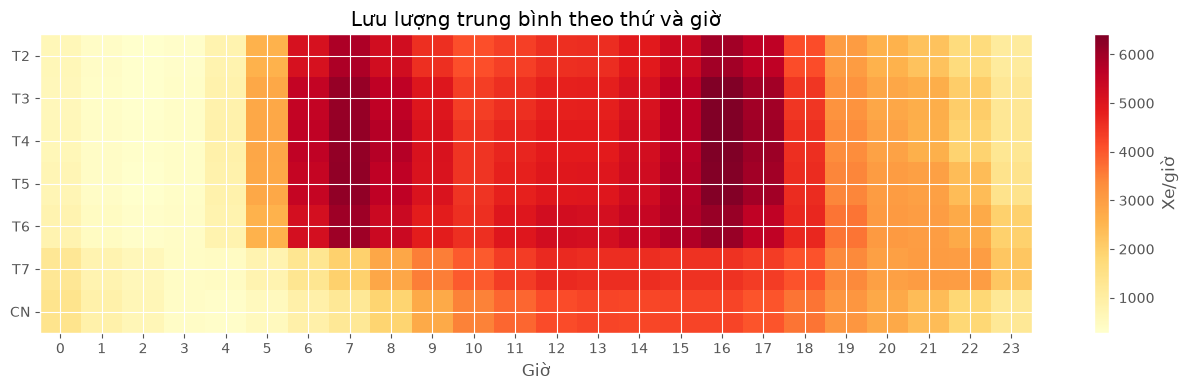

In [30]:
pivot = hourly.pivot_table(index="weekday", columns="hour", values="traffic_volume", aggfunc="mean")
fig, ax = plt.subplots(figsize=(13, 4))
im = ax.imshow(pivot, aspect="auto", cmap="YlOrRd")
ax.set(xticks=range(24), yticks=range(7), yticklabels=["T2", "T3", "T4", "T5", "T6", "T7", "CN"], xlabel="Giờ", title="Lưu lượng trung bình theo thứ và giờ")
fig.colorbar(im, ax=ax, label="Xe/giờ")
plt.tight_layout()
plt.show()

In [31]:
count_pivot = hourly.pivot_table(
    index="weekday",
    columns="hour",
    values="traffic_volume",
    aggfunc="count"
)

print("Số timestamp trong từng nhóm thứ × giờ:")
display(count_pivot)

Số timestamp trong từng nhóm thứ × giờ:


hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
weekday,,,,,,,,,,,,,,,,,,,,,,,,
0,249,240,246,240,242,247,243,245,237,236,240,239,241,239,238,239,238,238,240,245,240,249,243,245
1,245,240,240,238,243,232,239,227,236,232,242,234,241,233,239,234,239,232,234,234,241,241,243,244
2,247,239,245,233,243,237,244,233,244,228,250,237,242,233,248,240,252,232,247,239,250,240,250,250
3,242,247,241,238,243,237,240,238,241,234,238,239,242,238,244,239,247,237,244,242,247,245,244,250
4,251,248,246,248,243,244,243,245,241,240,246,245,242,241,244,238,244,245,242,247,245,247,246,256
5,247,251,240,238,243,244,232,245,243,235,243,235,243,244,241,234,241,237,240,237,240,238,246,247
6,242,245,239,234,246,244,242,239,247,234,246,238,241,245,243,239,246,243,235,239,246,244,247,248


In [32]:
# Giờ có lưu lượng trung bình cao nhất theo từng thứ
peak_by_day = hourly.groupby(["weekday", "hour"])["traffic_volume"].mean()
peak_by_day = peak_by_day.reset_index()

peak_by_day = peak_by_day.loc[
    peak_by_day.groupby("weekday")["traffic_volume"].idxmax()
].sort_values("weekday")

peak_by_day["thu"] = peak_by_day["weekday"].map({
    0: "Thứ Hai",
    1: "Thứ Ba",
    2: "Thứ Tư",
    3: "Thứ Năm",
    4: "Thứ Sáu",
    5: "Thứ Bảy",
    6: "Chủ nhật",
})

display(peak_by_day[["thu", "hour", "traffic_volume"]])

,thu,hour,traffic_volume
16,Thứ Hai,16,5966.974790
40,Thứ Ba,16,6389.142259
64,Thứ Tư,16,6414.261905
88,Thứ Năm,16,6344.259109
112,Thứ Sáu,16,6079.118852
132,Thứ Bảy,12,4650.518519
160,Chủ nhật,16,4248.325203


**Nhận xét:**

- Vào các ngày làm việc, lưu lượng có những thời điểm cao vào buổi
  sáng và chiều; giờ cao nhất theo từng thứ được thể hiện trong bảng.
- Vào cuối tuần, lưu lượng cao tập trung hơn vào khoảng giữa ngày.
- Bảng số lượng timestamp cho biết mỗi giá trị trung bình được tính
  từ bao nhiêu quan sát.
- Giờ, thứ trong tuần và cuối tuần là các đặc trưng có thể thử nghiệm
  trong mô hình.

## 4. Thời tiết và ngày lễ
Các phân tích sau dùng dòng gốc vì một timestamp có thể có nhiều mô tả thời tiết; do đó số dòng không tương đương số giờ độc lập. Ngày lễ được ghi tại một số timestamp, nên so sánh sau chỉ mang tính mô tả, không đại diện toàn bộ ngày lễ.

### 4.1. Lưu lượng theo loại thời tiết

,so_gio,traffic_mean,traffic_median
weather_main,,,
Clouds,15127,3616.9,4070.0
Clear,13371,3055.7,3043.0
Mist,5940,2933.1,2800.0
Rain,5563,3322.4,3500.0
Snow,2795,3009.3,3066.0
Drizzle,1792,3286.6,3470.5
Haze,1359,3501.3,3983.0
Thunderstorm,1010,3009.9,3006.5
Fog,912,2703.7,2339.0


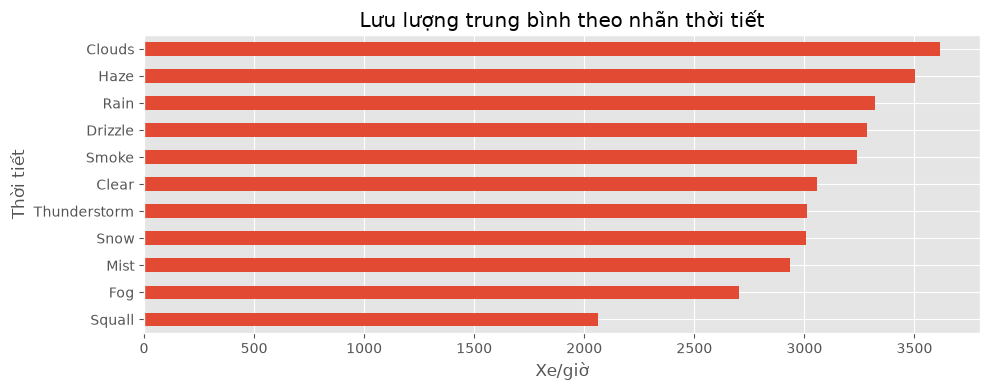

In [33]:
weather_rows = df[["date_time", "weather_main", "traffic_volume"]].drop_duplicates()
weather = weather_rows.groupby("weather_main")["traffic_volume"].agg(
    so_gio="size", traffic_mean="mean", traffic_median="median"
)
display(weather.sort_values("so_gio", ascending=False).round(1))

ax = weather["traffic_mean"].sort_values().plot.barh(figsize=(10, 4))
ax.set(title="Lưu lượng trung bình theo nhãn thời tiết", xlabel="Xe/giờ", ylabel="Thời tiết")
plt.tight_layout()
plt.show()

**Nhận xét.** Có 5.349 giờ mang nhiều nhãn. Một giờ được đếm một lần trong mỗi nhóm và có thể thuộc nhiều nhóm. Đọc mức trung bình cùng số giờ trong bảng. Giờ trong ngày và mùa có thể giải thích một phần chênh lệch.

### 4.2. Mối liên hệ giữa mưa, thời tiết và tỷ lệ mây

In [34]:
weather_numeric = [
    "temp",
    "rain_1h",
    "snow_1h",
    "clouds_all",
    "traffic_volume",
]

weather_corr = df[weather_numeric].corr()
display(weather_corr)

,temp,rain_1h,snow_1h,clouds_all,traffic_volume
temp,1.000000,0.009069,-0.019755,-0.101976,0.130299
rain_1h,0.009069,1.000000,-0.000090,0.004818,0.004714
snow_1h,-0.019755,-0.000090,1.000000,0.027931,0.000733
clouds_all,-0.101976,0.004818,0.027931,1.000000,0.067054
traffic_volume,0.130299,0.004714,0.000733,0.067054,1.000000


In [35]:
weather_details = (
    df.groupby("weather_main")
    .agg(
        so_dong=("date_time", "size"),
        so_timestamp=("date_time", "nunique"),
        mua_trung_binh=("rain_1h", "mean"),
        mua_trung_vi=("rain_1h", "median"),
        may_trung_binh=("clouds_all", "mean"),
        may_trung_vi=("clouds_all", "median"),
    )
    .sort_values("so_dong", ascending=False)
)

display(weather_details)

,so_dong,so_timestamp,mua_trung_binh,mua_trung_vi,may_trung_binh,may_trung_vi
weather_main,,,,,,
Clouds,15164,15127,0.000000,0.000,64.056120,75.0
Clear,13391,13371,0.000000,0.000,1.546710,1.0
Mist,5950,5940,0.238336,0.000,65.956303,90.0
Rain,5672,5563,2.281056,0.000,72.599788,90.0
Snow,2876,2795,0.025223,0.000,81.465229,90.0
Drizzle,1821,1792,0.157512,0.000,82.319605,90.0
Haze,1360,1359,0.046868,0.000,58.670588,75.0
Thunderstorm,1034,1010,1.189246,0.000,68.515474,90.0
Fog,912,912,0.087007,0.000,51.497807,75.0


In [36]:
rain_review = df[
    (df["rain_1h"] > 0)
    & (df["weather_main"] != "Rain")
]

print(
    "Số dòng có mưa nhưng weather_main khác Rain:",
    len(rain_review)
)

display(
    rain_review[
        [
            "date_time",
            "rain_1h",
            "clouds_all",
            "weather_main",
            "weather_description",
        ]
    ].head(20)
)

Số dòng có mưa nhưng weather_main khác Rain: 1404


,date_time,rain_1h,clouds_all,weather_main,weather_description
6694,2013-06-05 15:00:00,0.25,92,Drizzle,drizzle
6701,2013-06-05 20:00:00,0.57,92,Mist,mist
6703,2013-06-05 21:00:00,0.25,90,Drizzle,drizzle
6705,2013-06-05 22:00:00,0.25,92,Drizzle,light intensity drizzle
6707,2013-06-05 23:00:00,0.38,92,Drizzle,light intensity drizzle
6709,2013-06-06 00:00:00,0.25,92,Mist,mist
6711,2013-06-06 01:00:00,0.25,92,Mist,mist
6714,2013-06-06 03:00:00,0.25,92,Mist,mist
6716,2013-06-06 04:00:00,0.30,90,Mist,mist
6717,2013-06-06 04:00:00,0.30,90,Drizzle,drizzle


**Nhận xét:**

- Tương quan Pearson giữa `rain_1h` và `clouds_all` trên dữ liệu dòng
  gốc khoảng 0,0048, cho thấy tương quan tuyến tính rất yếu trong
  phép tính này.
- Có 1.404 dòng có `rain_1h > 0` nhưng `weather_main` khác `Rain`.
  Những trường hợp này cần tìm hiểu thêm và chưa thể xem ngay là lỗi.
- Giá trị mưa cực lớn và các timestamp lặp có thể ảnh hưởng đến thống
  kê và tương quan.
- Nên so sánh thêm kết quả trước và sau khi xử lý giá trị mưa nghi vấn,
  đồng thời cân nhắc cách biểu diễn dữ liệu theo từng giờ.

### 4.3. Kiểm tra nhãn ngày lễ

Kiểm tra thời điểm xuất hiện nhãn lễ và xem nhãn có đại diện cho
toàn bộ các giờ trong ngày hay không.

In [37]:
holiday_label = df["holiday"].astype("string").str.strip()

df["holiday_flag"] = (
    holiday_label.notna()
    & holiday_label.ne("")
    & holiday_label.str.lower().ne("none")
)

holiday_rows = df.loc[df["holiday_flag"]].copy()

print("Số dòng có nhãn lễ:", len(holiday_rows))
print(
    "Số ngày có nhãn lễ:",
    holiday_rows["date_time"].dt.date.nunique()
)

print("Số dòng có nhãn lễ theo giờ:")
display(
    holiday_rows["date_time"].dt.hour
    .value_counts()
    .sort_index()
    .rename("so_dong")
    .to_frame()
)

Số dòng có nhãn lễ: 61
Số ngày có nhãn lễ: 53
Số dòng có nhãn lễ theo giờ:


,so_dong
date_time,
0,61


In [38]:
print("Các timestamp có nhãn lễ:")
display(
    holiday_rows[
        ["date_time", "holiday", "traffic_volume"]
    ].sort_values("date_time")
)

if not holiday_rows.empty:
    example_date = holiday_rows["date_time"].dt.date.iloc[0]
    print("Các bản ghi trong ngày ví dụ:", example_date)

    display(
        df.loc[
            df["date_time"].dt.date == example_date,
            ["date_time", "holiday", "traffic_volume"]
        ].sort_values("date_time")
    )

Các timestamp có nhãn lễ:


,date_time,holiday,traffic_volume
126,2012-10-08,Columbus Day,455
1123,2012-11-12,Veterans Day,1000
1370,2012-11-22,Thanksgiving Day,919
2360,2012-12-25,Christmas Day,803
2559,2013-01-01,New Years Day,1439
...,...,...,...
44441,2018-05-28,Memorial Day,1088
45547,2018-07-04,Independence Day,1021
46936,2018-08-23,State Fair,596
47330,2018-09-03,Labor Day,962


Các bản ghi trong ngày ví dụ: 2012-10-08


,date_time,holiday,traffic_volume
126,2012-10-08 00:00:00,Columbus Day,455
127,2012-10-08 01:00:00,None,336
128,2012-10-08 02:00:00,None,265
129,2012-10-08 03:00:00,None,314
130,2012-10-08 04:00:00,None,779
131,2012-10-08 05:00:00,None,2571
132,2012-10-08 06:00:00,None,5563
133,2012-10-08 07:00:00,None,6676
134,2012-10-08 08:00:00,None,5966
135,2012-10-08 09:00:00,None,4832


In [39]:
display(
    df.groupby("holiday_flag")["traffic_volume"]
    .agg(["mean", "median", "count"])
)

,mean,median,count
holiday_flag,,,
False,3262.852170,3385.0,48143
True,865.442623,812.0,61


In [40]:
observed_by_day = hourly.groupby(hourly["date_time"].dt.normalize()).size()
days_with_label = holiday_rows["date_time"].dt.normalize().drop_duplicates()
holiday_coverage = observed_by_day.reindex(days_with_label)
print(f"{holiday_coverage.lt(24).sum()}/{len(holiday_coverage)} ngày có nhãn bị thiếu giờ.")
display(holiday_coverage.nsmallest(5).rename("Giờ quan sát"))

17/53 ngày có nhãn bị thiếu giờ.


date_time
2013-10-14    12
2015-11-11    13
2015-11-26    14
2016-01-01    18
2015-12-25    19
Name: Giờ quan sát, dtype: int64

**Nhận xét.** 61 dòng nhãn đều ở 00h, tương ứng 53 ngày. Có 17/53 ngày thiếu giờ quan sát. Khi phân tích V2, gắn nhãn theo ngày và báo số giờ quan sát được.

### 4.4. Tương quan giữa thời tiết và lưu lượng

In [41]:
weather_hour = df[["date_time", *weather_cols]].copy()
weather_hour.loc[weather_hour["temp"].eq(0), "temp"] = pd.NA
peak = weather_hour["date_time"].eq(pd.Timestamp("2016-07-11 17:00")) & weather_hour["rain_1h"].eq(9831.3)
weather_hour.loc[peak, "rain_1h"] = pd.NA
weather_hour = weather_hour.groupby("date_time")[weather_cols].agg(lambda s: s.drop_duplicates().median())
analysis = hourly.set_index("date_time")[["traffic_volume"]].join(weather_hour)

In [42]:
target = "traffic_volume"
corr = pd.DataFrame({
    "Pearson dòng gốc": df[[*weather_cols, target]].corr()[target],
    "Pearson theo giờ": analysis.corr()[target],
    "Spearman theo giờ": analysis.corr(method="spearman")[target],
    "Số giờ": analysis[weather_cols].notna().sum(),
}).loc[weather_cols]
display(corr.round(4))

,Pearson dòng gốc,Pearson theo giờ,Spearman theo giờ,Số giờ
temp,0.1303,0.1392,0.1401,40565.0
rain_1h,0.0047,-0.0134,0.0043,40574.0
snow_1h,0.0007,-0.0021,-0.0052,40575.0
clouds_all,0.0671,0.0783,0.0729,40575.0


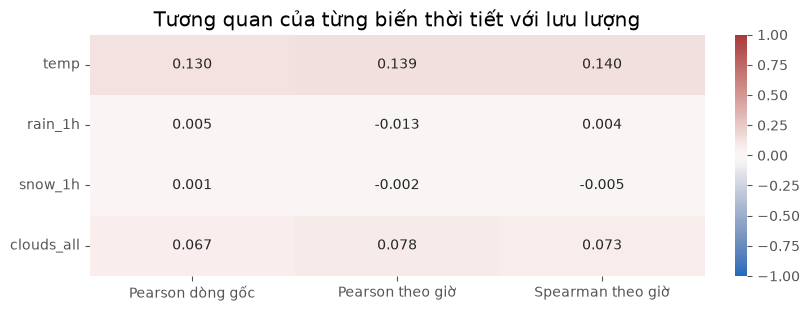

In [43]:
fig, ax = plt.subplots(figsize=(8, 3), layout="constrained")
sns.heatmap(corr.iloc[:, :3], annot=True, fmt=".3f", center=0, vmin=-1, vmax=1, cmap="vlag", ax=ax)
ax.set_title("Tương quan của từng biến thời tiết với lưu lượng")
plt.show()

**Nhận xét.** Theo giờ, nhiệt độ có Pearson 0.139 và Spearman 0.140. Lượng mưa có Pearson -0.013. Bảng theo giờ vừa đổi đơn vị phân tích vừa đánh dấu 0 K và điểm mưa nghi vấn trước khi gộp. V3 cần đối chứng A–B để đo ích lợi dự đoán.

## 5. Kết luận và bàn giao

### Phát hiện chính

- Lưu lượng có quy luật theo giờ và thứ trong tuần. Trong dữ liệu này,
  lưu lượng trung bình cao nhất vào 16 giờ và thấp nhất vào 3 giờ.
- Lưu lượng cuối tuần nhìn chung thấp hơn ngày làm việc; cần xem thêm
  heatmap để mô tả sự khác biệt theo từng khoảng giờ.
- Tương quan tuyến tính riêng lẻ giữa các biến thời tiết được khảo sát
  và lưu lượng tương đối yếu. Kết quả này chưa loại trừ quan hệ
  phi tuyến hoặc ảnh hưởng kết hợp với thời gian.

### Chất lượng dữ liệu

- Một số timestamp xuất hiện nhiều dòng; lưu lượng trong cùng timestamp
  không mâu thuẫn nhưng thông tin thời tiết có thể khác nhau.
- Có 11.976 giờ không có bản ghi, bao gồm một khoảng thiếu dài.
- Nhiệt độ 0 K, lượng mưa cực lớn và các giờ lưu lượng bằng 0 cần
  được xác minh hoặc xử lý phù hợp.
- Có khác biệt cách viết trong `weather_description`; đã tạo cột
  chuẩn hóa để hỗ trợ phân tích.
- Nhãn ngày lễ xuất hiện lúc 0 giờ và chưa đại diện cho toàn bộ ngày.

### Nội dung bàn giao cho tiền xử lý

- Kiểm tra timestamp lặp trước khi gộp: lưu lượng cùng timestamp
  nhất quán trong dữ liệu hiện tại, nhưng thời tiết có thể khác nhau.
- Xem xét các khoảng thiếu giờ khi tạo đặc trưng theo thời gian.
- Xác minh nhiệt độ 0 K, lượng mưa cực lớn và các giờ lưu lượng bằng 0.
- Thống nhất cách chuẩn hóa `weather_description`.
- Đối chiếu nguồn hoặc lịch trước khi tạo nhãn ngày lễ cho cả ngày.

Đây là các phát hiện và đề xuất từ EDA. Quy tắc xử lý chính thức cần
được nhóm thống nhất và triển khai trong pipeline tiền xử lý.

### Các việc cần tiếp tục

- Xác minh và thống nhất cách xử lý nhiệt độ 0 K, lượng mưa cực lớn
  và các giờ lưu lượng bằng 0.
- Thống nhất cách sử dụng nhiều mô tả thời tiết trong cùng timestamp.
- Đối chiếu nguồn dữ liệu hoặc lịch trước khi tạo nhãn cho cả ngày lễ.
- Kiểm tra tác động của khoảng thiếu giờ khi tạo đặc trưng lịch sử.